# Figure 4a — UMAP of gRNA LFC across tissue contexts, all screens

Kexin Dong

Last Updated: November 19, 2026

Generalizes the published Figure 4a panel (originally
`SG-B-ALL-in-vivo-base-editing/figure3a_UMAP.ipynb`) to **every ABE and CBE
arm**: the OG screens and all focused (FC) sub-pools.

Each gRNA is embedded by its vector of median LFCs across tissue contexts;
the embedding is then re-colored once per tissue. gRNAs that sit together
behave similarly across contexts, so context-specific behaviour shows up as
regions that flip colour between panels.

**One PDF per arm**, each panelled by every tissue in that arm, written to
`figures/figure4a-umap/`.

### Differences from the original notebook

| | Original (`figure3a_UMAP.ipynb`) | Here |
|---|---|---|
| Input | `ABE_LFC_FDR_df.csv`, `CBE_LFC_FDR_df.csv` | `LFC-FDR/*_LFC_FDR.csv` (current tables) |
| Tissue cols | `_bonemarrow`, `_meninges` | `_bm`, `_men` |
| Embedding | ABE+CBE pooled, one figure | **per arm**, independent embeddings |
| Seed | unset — layout not reproducible | `random_state=RANDOM_STATE` (pinned) |
| Highlights | hard-coded `g_list` of gRNA IDs | optional, off by default |

> **Note on arms.** OG screens have meninges; focused screens do not (they
> carry an `input` arm instead). Each figure is panelled by whatever tissues
> its own table actually contains, so panel counts differ between arms.
>
> **D5 is excluded** (`TISSUE_ORDER`). It is the earliest in vitro timepoint,
> before selection has had time to act. Because the embedding is fit on the
> same tissue list that is plotted, dropping D5 also refits the UMAP — so
> these layouts differ from the earlier D5-inclusive version.

> **Requires `umap-learn`** (installed in the base conda env:
> `pip install umap-learn`). UMAP layout depends on the random seed — it is
> pinned below, but changing `RANDOM_STATE`, the tissue set, or the filters
> will change the picture. UMAP distances are **not** metric: read clusters
> and neighbourhoods, not absolute positions or axis units.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import cm, colors
import seaborn as sns
import umap

warnings.filterwarnings('ignore')

# ── Global style: final print size, Nature look ───────────────────────────
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
mpl.rcParams['text.usetex'] = False
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']
mpl.rcParams.update({'mathtext.fontset': 'custom', 'mathtext.rm': 'Helvetica',
                     'mathtext.it': 'Arial:italic', 'mathtext.bf': 'Arial:bold'})
mpl.rcParams.update({'font.size': 7, 'axes.labelsize': 7, 'axes.titlesize': 7,
                     'xtick.labelsize': 6, 'ytick.labelsize': 6,
                     'legend.fontsize': 6, 'axes.linewidth': .6,
                     'lines.linewidth': .75, 'patch.linewidth': .5,
                     'xtick.major.width': .6, 'ytick.major.width': .6,
                     'xtick.major.size': 3, 'ytick.major.size': 3,
                     'legend.frameon': False, 'figure.dpi': 200})
MM = 1 / 25.4

BASE = '/Users/kexindong/Documents/GitHub/B-ALL-in-vivo-base-editing/'
OUT_DIR = BASE + 'figures/figure4a-umap/'
os.makedirs(OUT_DIR, exist_ok=True)
print('writing to', OUT_DIR)

/opt/miniconda3/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


writing to /Users/kexindong/Documents/GitHub/B-ALL-in-vivo-base-editing/figures/figure4a-umap/


## Parameters

`MIN_EDIT` filters to gRNAs whose sensor shows real editing — the same 20%
target-base-editing cutoff used in Figure 2. Guides below it have a
meaningless LFC, so letting them into the embedding would place noise next to
signal. Set it to 0 to embed everything.

In [2]:
# ── Embedding / filtering constants ───────────────────────────────────────
RANDOM_STATE = 0      # pin the layout; the original notebook left this unset
MIN_DIST     = 0.8    # as in the published panel
N_NEIGHBORS  = 15     # umap default
MIN_EDIT     = 20     # % target base editing, matches the Fig. 2 cutoff
MIN_INPUT    = 2      # median input counts
TARGETING_ONLY = True # drop safe-/non-targeting controls from the embedding

# Colour scale for LFC (seismic, symmetric) — as in the published panel
VMIN, VMAX = -5, 5
# Hexbin resolution. A FIXED gridsize makes density depend on library size:
# at gridsize=30 the 10k-gRNA CBE OG arm averages ~13 gRNAs per cell, while
# the 852-gRNA ABE OG arm averages 1 (50% of its cells hold a single guide,
# so the 'local mean' is really one guide's noise, and empty cells show as
# white gaps). Scaling with sqrt(n) holds occupancy near TARGET_PER_CELL
# for every arm. Set GRIDSIZE_FIXED to an int to override.
TARGET_PER_CELL = 3       # aimed median gRNAs per hexagon
GRIDSIZE_MIN    = 8
GRIDSIZE_MAX    = 30
GRIDSIZE_FIXED  = None    # e.g. 30 to reproduce the original look


def gridsize_for(n):
    """Hexbin gridsize that keeps ~TARGET_PER_CELL gRNAs per cell."""
    if GRIDSIZE_FIXED:
        return GRIDSIZE_FIXED
    gs = int(round((n / TARGET_PER_CELL) ** .5 / 1.07))
    return max(GRIDSIZE_MIN, min(GRIDSIZE_MAX, gs))

# Optional highlight groups: {'label': ['gRNA_1', ...]}. Empty = no overlay.
# The published panel overlaid three hand-curated sets; left off by default
# because those IDs are specific to the OG screens.
HIGHLIGHTS = {}
HIGHLIGHT_PALETTE = ['#F9CBA8', '#ED6A50', '#7284A1', 'darkslategray', 'lightgrey']

## Arms

Every `LFC-FDR/*.csv` table, grouped into OG and focused (FC) screens. The
`_FSR` variants are a different replicate set of the same focused arms; they
are listed but switched off by default — flip `INCLUDE_FSR` to emit them too.

In [3]:
INCLUDE_FSR = False

ARMS = {
    # --- OG screens (have meninges) ---
    'ABE_OG':            'LFC-FDR/ABE_OG_LFC_FDR.csv',
    'CBE_OG':            'LFC-FDR/CBE_OG_LFC_FDR.csv',
    # --- focused sub-pools (no meninges) ---
    'ABE_FC_EPO_T0':     'LFC-FDR/ABE_FC_EPO_T0_LFC_FDR.csv',
    'CBE_FC_EPO_T0':     'LFC-FDR/CBE_FC_EPO_T0_LFC_FDR.csv',
    'ABE_FC_BC_T0':      'LFC-FDR/ABE_FC_BC_T0_LFC_FDR.csv',
    'CBE_FC_BC_T0':      'LFC-FDR/CBE_FC_BC_T0_LFC_FDR.csv',
    'ABE_FC_EPO_TO_BC':  'LFC-FDR/ABE_FC_EPO_TO_BC_LFC_FDR.csv',
    'CBE_FC_EPO_TO_BC':  'LFC-FDR/CBE_FC_EPO_TO_BC_LFC_FDR.csv',
}

ARMS_FSR = {
    'ABE_FC_EPO_T0_FSR':    'LFC-FDR/ABE_FC_EPO_T0_LFC_FDR_FSR.csv',
    'CBE_FC_EPO_T0_FSR':    'LFC-FDR/CBE_FC_EPO_T0_LFC_FDR_FSR.csv',
    'ABE_FC_BC_T0_FSR':     'LFC-FDR/ABE_FC_BC_T0_LFC_FDR_FSR.csv',
    'CBE_FC_BC_T0_FSR':     'LFC-FDR/CBE_FC_BC_T0_LFC_FDR_FSR.csv',
    'ABE_FC_EPO_TO_BC_FSR': 'LFC-FDR/ABE_FC_EPO_TO_BC_LFC_FDR_FSR.csv',
    'CBE_FC_EPO_TO_BC_FSR': 'LFC-FDR/CBE_FC_EPO_TO_BC_LFC_FDR_FSR.csv',
}

if INCLUDE_FSR:
    ARMS = {**ARMS, **ARMS_FSR}

# Tissue display names, in the order panels should appear.
# 'd15' is the in vitro arm (labelled 'In Vitro' in the published figure).
TISSUE_LABEL = {
    'd5':     'D5',
    'd15':    'In Vitro',
    'spleen': 'Spleen',
    'bm':     'Bone Marrow',
    'men':    'Meninges',
    'input':  'Input',
    'lib':    'Plasmid',
}
# Panel order; tissues absent from a given table are skipped automatically.
# D5 is excluded: it is the earliest in vitro timepoint, before selection has
# had time to act, so it contributes little signal. Both the embedding and the
# panels derive from this list, so dropping it here refits the UMAP without it.
TISSUE_ORDER = ['d15', 'spleen', 'bm', 'men']

print(f'{len(ARMS)} arms queued')

8 arms queued


## Build the embedding for one arm

The embedding is fit on the per-tissue `LFC_median_*` columns of that arm
only, so coordinates are **not** comparable between arms — each figure is
internally consistent and that is all.

Guides with a missing LFC in any tissue are dropped (UMAP cannot take NaN);
the count is reported so the loss is visible rather than silent.

In [4]:
def tissues_in(df):
    """Tissue keys present in this table, in TISSUE_ORDER, that have LFC+edit data."""
    out = []
    for t in TISSUE_ORDER:
        if f'LFC_median_{t}' in df.columns:
            out.append(t)
    return out


def prepare(path):
    """Load one arm, filter, and return (table, tissue keys, filter report)."""
    df = pd.read_csv(BASE + path, low_memory=False)
    n0 = len(df)
    report = {'loaded': n0}

    if TARGETING_ONLY and 'classification' in df.columns:
        df = df[df['classification'] == 'targeting guide']
        report['targeting'] = len(df)

    if MIN_INPUT and 'Input_median' in df.columns:
        df = df[df['Input_median'] >= MIN_INPUT]
        report['input_ok'] = len(df)

    tis = tissues_in(df)

    # editing filter: require the cutoff in at least one tissue of this arm,
    # so a guide that edits well somewhere is kept for every panel
    if MIN_EDIT:
        edit_cols = [f'target_base_edit_perc_{t}' for t in tis
                     if f'target_base_edit_perc_{t}' in df.columns]
        if edit_cols:
            df = df[(df[edit_cols] >= MIN_EDIT).any(axis=1)]
            report['edit_ok'] = len(df)

    lfc_cols = [f'LFC_median_{t}' for t in tis]
    before = len(df)
    df = df.dropna(subset=lfc_cols)
    report['dropped_na'] = before - len(df)
    report['final'] = len(df)
    return df.reset_index(drop=True), tis, report


def embed(df, tis):
    """Fit UMAP on this arm's tissue LFC matrix."""
    X = df[[f'LFC_median_{t}' for t in tis]].values
    n_neighbors = min(N_NEIGHBORS, max(2, len(df) - 1))
    reducer = umap.UMAP(min_dist=MIN_DIST, n_neighbors=n_neighbors,
                        random_state=RANDOM_STATE)
    return reducer.fit_transform(X)

## Draw one arm

`hexbin` with `C=` averages the LFC of the gRNAs falling in each cell, so the
colour is a local mean rather than a single guide — the same construction as
the published panel. Axes are bare: UMAP units carry no meaning.

**Resolution is adaptive.** Arms differ in size by ~60x (169 to 10,303 gRNAs),
so a fixed `gridsize` would make the hexagons mean different things in
different figures: at `gridsize=30` the CBE OG arm averaged ~13 gRNAs per
cell, while ABE OG averaged 1 — half its cells held a single guide, so the
'local mean' was one guide's noise and unfilled cells appeared as white gaps.
`gridsize_for()` scales with sqrt(n) to hold occupancy near
`TARGET_PER_CELL`, so a hexagon carries comparable evidence in every arm.
The chosen gridsize is printed in each figure title and recorded in the
summary table.


In [5]:
def plot_arm(name, df, tis, emb, show=True):
    n = len(tis)
    gs = gridsize_for(len(df))
    # last panel is wider to host the colourbar, as in the published figure
    widths = [1] * (n - 1) + [1.2]
    fig, axs = plt.subplots(1, n, figsize=(40 * n * MM, 46 * MM),
                            width_ratios=widths, sharex=True, sharey=True)
    axs = np.atleast_1d(axs)

    for i, t in enumerate(tis):
        ax = axs[i]
        im = ax.hexbin(emb[:, 0], emb[:, 1], C=df[f'LFC_median_{t}'],
                       vmin=VMIN, vmax=VMAX, gridsize=gs,
                       linewidths=.2, cmap='seismic', bins=None)
        # italic title via fontstyle (mathtext collapses spaces in 'In Vitro')
        ax.set_title(TISSUE_LABEL.get(t, t), fontsize=7, fontstyle='italic')
        ax.spines[['top', 'right', 'bottom', 'left']].set_visible(False)
        ax.set_xticks([]); ax.set_yticks([])

        # optional highlight overlay
        for j, (lab, ids) in enumerate(HIGHLIGHTS.items()):
            sel = df['gRNA_id'].isin(ids).values
            if sel.any():
                ax.scatter(emb[sel, 0], emb[sel, 1], s=12,
                           color=HIGHLIGHT_PALETTE[j % len(HIGHLIGHT_PALETTE)],
                           edgecolors='black', linewidths=.4, zorder=3,
                           label=lab if i == 0 else None)
        if i == 0 and HIGHLIGHTS:
            ax.legend(loc='upper left', fontsize=5, frameon=False)

    # axis-direction arrows on the first panel (UMAP 1 / UMAP 2)
    a0 = axs[0]
    a0.annotate('', xy=(.22, -.02), xytext=(.02, -.02), xycoords='axes fraction',
                arrowprops=dict(arrowstyle='->', lw=.8, color='black'))
    a0.annotate('', xy=(.02, .22), xytext=(.02, .02), xycoords='axes fraction',
                arrowprops=dict(arrowstyle='->', lw=.8, color='black'))
    a0.text(.12, -.07, 'UMAP 1', transform=a0.transAxes, fontsize=5.5,
            ha='center', va='top')
    a0.text(-.035, .12, 'UMAP 2', transform=a0.transAxes, fontsize=5.5,
            ha='right', va='center', rotation=90)

    cb = fig.colorbar(im, ax=axs[-1], fraction=.09, pad=.04)
    cb.set_label('LFC\n(vs. Input)', fontsize=6)
    cb.ax.tick_params(labelsize=5.5)
    cb.outline.set_visible(False)

    fig.suptitle(f'{name.replace("_", " ")} — n = {len(df):,} gRNAs '
                 f'(gridsize {gs})', fontsize=8, fontweight='bold', y=1.06)
    fig.tight_layout()
    out = f'{OUT_DIR}{name}_UMAP.pdf'
    fig.savefig(out, bbox_inches='tight')
    if show:
        plt.show()
    plt.close(fig)
    return out, gs


## Run every arm

Each arm is fit and saved independently, so one failing table does not stop
the rest. The summary table at the end records how many gRNAs survived each
filter — check it before trusting a sparse panel.

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Zapf NOT subset; don't know how to subset; dropped


feat NOT subset; don't know how to subset; dropped


morx NOT subset; don't know how to subset; dropped


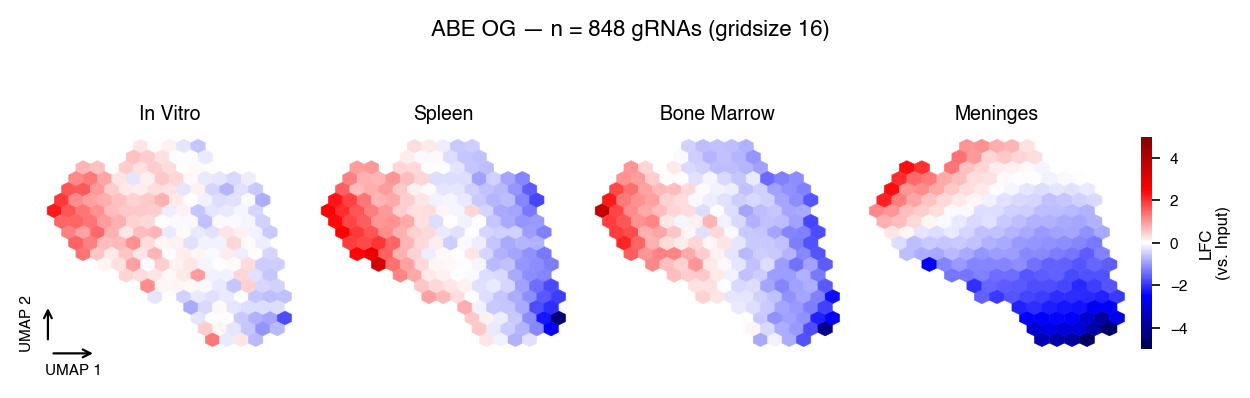

✓ ABE_OG: 848 gRNAs, 4 panels -> ABE_OG_UMAP.pdf


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Zapf NOT subset; don't know how to subset; dropped


feat NOT subset; don't know how to subset; dropped


morx NOT subset; don't know how to subset; dropped


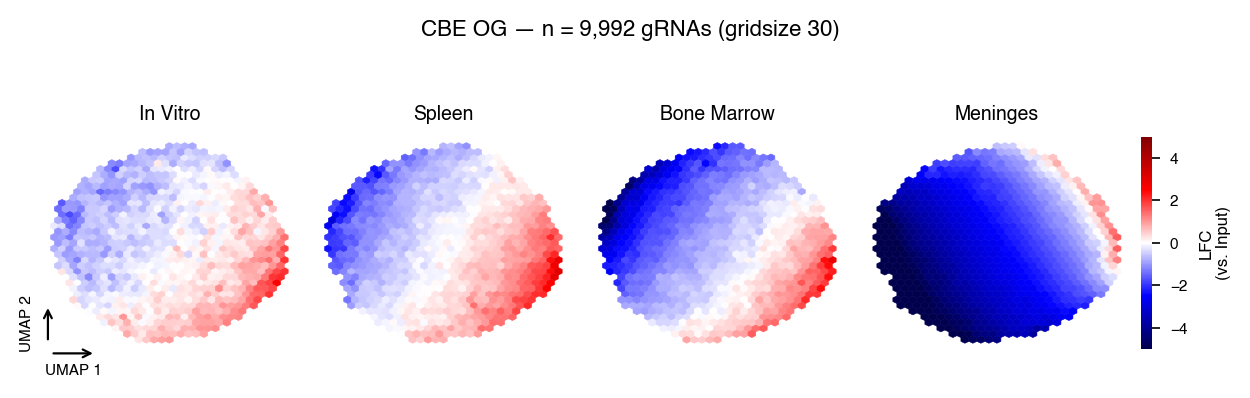

✓ CBE_OG: 9,992 gRNAs, 4 panels -> CBE_OG_UMAP.pdf


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Zapf NOT subset; don't know how to subset; dropped


feat NOT subset; don't know how to subset; dropped


morx NOT subset; don't know how to subset; dropped


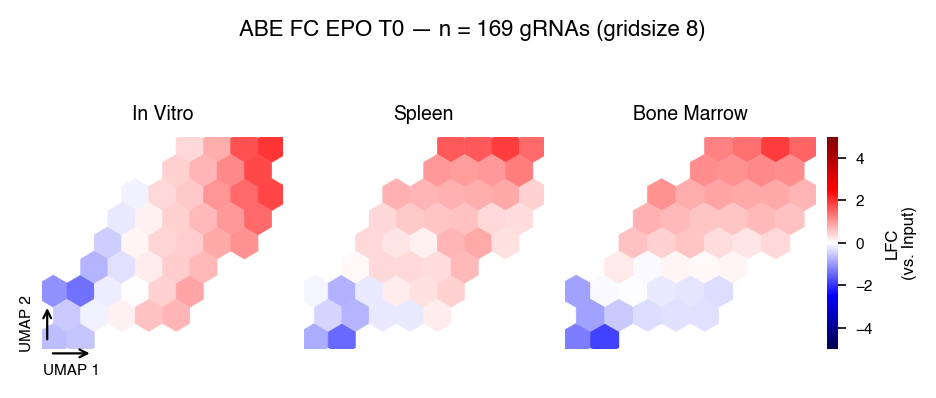

✓ ABE_FC_EPO_T0: 169 gRNAs, 3 panels -> ABE_FC_EPO_T0_UMAP.pdf


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Zapf NOT subset; don't know how to subset; dropped


feat NOT subset; don't know how to subset; dropped


morx NOT subset; don't know how to subset; dropped


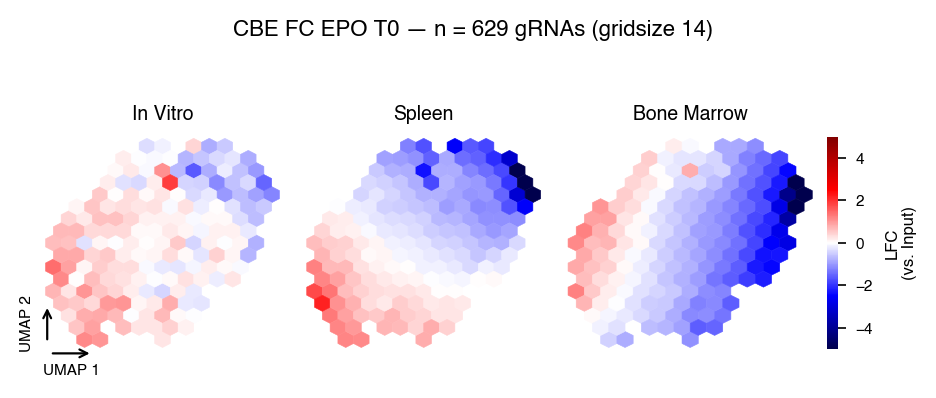

✓ CBE_FC_EPO_T0: 629 gRNAs, 3 panels -> CBE_FC_EPO_T0_UMAP.pdf


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Zapf NOT subset; don't know how to subset; dropped


feat NOT subset; don't know how to subset; dropped


morx NOT subset; don't know how to subset; dropped


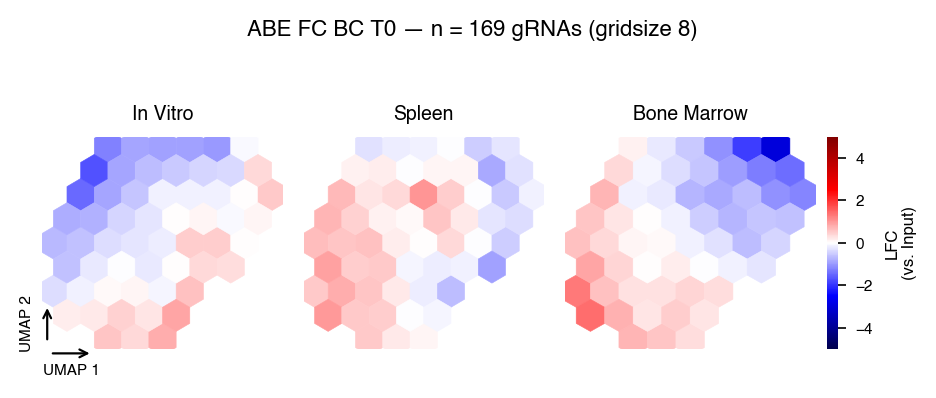

✓ ABE_FC_BC_T0: 169 gRNAs, 3 panels -> ABE_FC_BC_T0_UMAP.pdf


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Zapf NOT subset; don't know how to subset; dropped


feat NOT subset; don't know how to subset; dropped


morx NOT subset; don't know how to subset; dropped


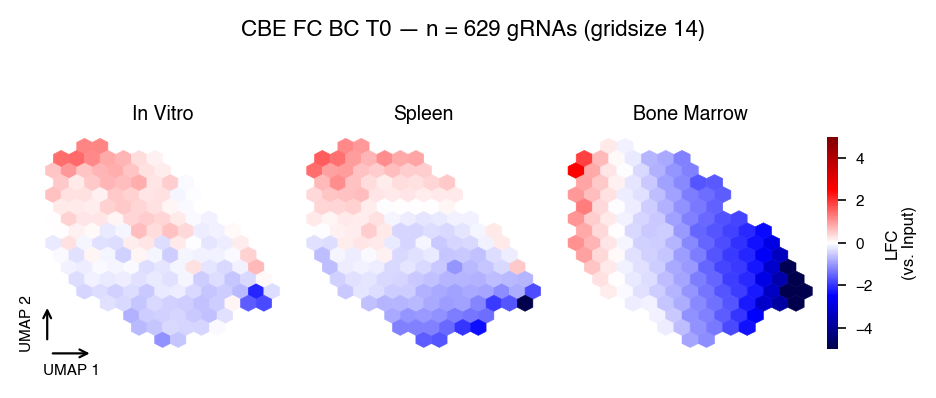

✓ CBE_FC_BC_T0: 629 gRNAs, 3 panels -> CBE_FC_BC_T0_UMAP.pdf


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Zapf NOT subset; don't know how to subset; dropped


feat NOT subset; don't know how to subset; dropped


morx NOT subset; don't know how to subset; dropped


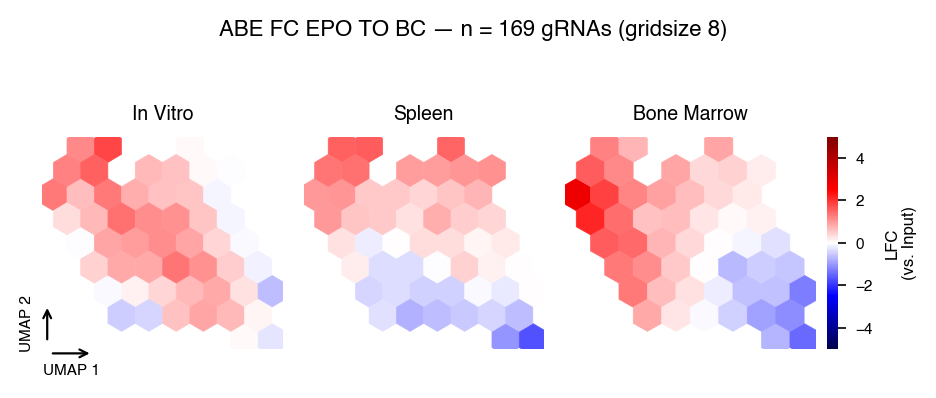

✓ ABE_FC_EPO_TO_BC: 169 gRNAs, 3 panels -> ABE_FC_EPO_TO_BC_UMAP.pdf


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Zapf NOT subset; don't know how to subset; dropped


feat NOT subset; don't know how to subset; dropped


morx NOT subset; don't know how to subset; dropped


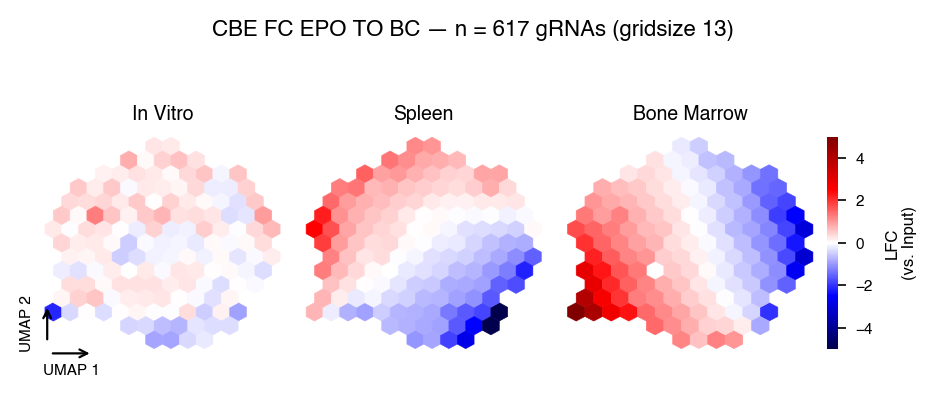

✓ CBE_FC_EPO_TO_BC: 617 gRNAs, 3 panels -> CBE_FC_EPO_TO_BC_UMAP.pdf


,arm,n_gRNA,tissues,gridsize,dropped_NA,pdf
0,ABE_OG,848,"In Vitro,Spleen,Bone Marrow,Meninges",16,0,ABE_OG_UMAP.pdf
1,CBE_OG,9992,"In Vitro,Spleen,Bone Marrow,Meninges",30,0,CBE_OG_UMAP.pdf
2,ABE_FC_EPO_T0,169,"In Vitro,Spleen,Bone Marrow",8,0,ABE_FC_EPO_T0_UMAP.pdf
3,CBE_FC_EPO_T0,629,"In Vitro,Spleen,Bone Marrow",14,0,CBE_FC_EPO_T0_UMAP.pdf
4,ABE_FC_BC_T0,169,"In Vitro,Spleen,Bone Marrow",8,0,ABE_FC_BC_T0_UMAP.pdf
5,CBE_FC_BC_T0,629,"In Vitro,Spleen,Bone Marrow",14,0,CBE_FC_BC_T0_UMAP.pdf
6,ABE_FC_EPO_TO_BC,169,"In Vitro,Spleen,Bone Marrow",8,0,ABE_FC_EPO_TO_BC_UMAP.pdf
7,CBE_FC_EPO_TO_BC,617,"In Vitro,Spleen,Bone Marrow",13,0,CBE_FC_EPO_TO_BC_UMAP.pdf


In [6]:
# clear previous PDFs so nothing stale survives a partial run
for _f in os.listdir(OUT_DIR):
    if _f.endswith('_UMAP.pdf'):
        os.remove(os.path.join(OUT_DIR, _f))

results = []
failures = []

for name, path in ARMS.items():
    if not os.path.exists(BASE + path):
        print(f'!! {name}: missing {path}')
        continue
    try:
        df, tis, rep = prepare(path)
        if len(df) < 10:
            print(f'!! {name}: only {len(df)} gRNAs after filtering — skipped')
            continue
        emb = embed(df, tis)
        out, gs = plot_arm(name, df, tis, emb)
        results.append({'arm': name, 'n_gRNA': len(df),
                        'tissues': ','.join(TISSUE_LABEL.get(t, t) for t in tis),
                        'gridsize': gs,
                        'dropped_NA': rep.get('dropped_na', 0),
                        'pdf': os.path.basename(out)})
        print(f'✓ {name}: {len(df):,} gRNAs, {len(tis)} panels -> {os.path.basename(out)}')
    except Exception as e:
        failures.append((name, f'{type(e).__name__}: {e}'))
        print(f'!! {name} FAILED: {type(e).__name__}: {e}')

summary = pd.DataFrame(results)

# Fail loudly: stale PDFs from an earlier run stay on disk, so a silently
# swallowed error can look like success. Raise if any arm did not render.
if failures:
    raise RuntimeError(
        f'{len(failures)}/{len(ARMS)} arms failed to render — PDFs in '
        f'{OUT_DIR} may be stale:\n' +
        '\n'.join(f'  {n}: {m}' for n, m in failures))

summary

## Summary

`n_gRNA` is the number embedded after the targeting / input / editing filters.
Arms differ in library size by more than an order of magnitude (ABE OG ~1k vs
CBE OG ~13k), so hexbin density is not comparable between figures — only the
colour pattern within one figure is.

In [7]:
summary.to_csv(OUT_DIR + 'umap_arm_summary.csv', index=False)
print('wrote', OUT_DIR + 'umap_arm_summary.csv')
print()
print(f'{len(summary)} figures in {OUT_DIR}:')
for f in sorted(os.listdir(OUT_DIR)):
    if f.endswith('.pdf'):
        print('  ', f)

wrote /Users/kexindong/Documents/GitHub/B-ALL-in-vivo-base-editing/figures/figure4a-umap/umap_arm_summary.csv

8 figures in /Users/kexindong/Documents/GitHub/B-ALL-in-vivo-base-editing/figures/figure4a-umap/:
   ABE_FC_BC_T0_UMAP.pdf
   ABE_FC_EPO_T0_UMAP.pdf
   ABE_FC_EPO_TO_BC_UMAP.pdf
   ABE_OG_UMAP.pdf
   CBE_FC_BC_T0_UMAP.pdf
   CBE_FC_EPO_T0_UMAP.pdf
   CBE_FC_EPO_TO_BC_UMAP.pdf
   CBE_OG_UMAP.pdf
